# A free 2D tissue: mask → mesh → tensions, pressures and stresses

This example runs foambryo's two-dimensional inference end to end on a real image: a 4-cell *C. elegans* embryo whose eggshell was removed, so that its cells are deformed by their own tensions and pressures only. It meshes the segmentation mask with delaunay-watershed's 2D mesher, reads the junction angles on circular arcs (the default reading in 2D), infers the tensions and the pressures, draws the cells' stresses, and compares the result with the opt-in global fit of an equilibrium tiling of circular arcs (`infer_forces_by_equilibrium_tiling`).

Everything 2D in foambryo is provisional: the names and signatures may change until they are declared stable. If you use foambryo, in 2D as in 3D, please cite both articles: Ichbiah S., Delbary F., McDougall A., Dumollard R., Turlier H. *Embryo mechanics cartography: inference of 3D force atlases from fluorescence microscopy.* Nature Methods 20(12), 1989–1999 (2023), doi:10.1038/s41592-023-02084-7; and Yamamoto K., Ichbiah S., Perez M., Borrego-Pinto J., Delbary F., Goehring N. W., Northrop P., Turlier H., Charras G. Spatiotemporal mapping of the contractile and adhesive forces sculpting early *C. elegans* embryos. *Developmental Cell* 61(6), 1273–1288.e4 (2026). doi:10.1016/j.devcel.2026.04.013.

**Data.** Three frames of embryo 190430-9 of that paper's public data (Zenodo, doi:10.5281/zenodo.19627642), CC BY-SA 4.0, in `Examples/data/` (see its README for how they were made). The two AB daughters are both ABx; where they must be told apart they are ABx1 and ABx2.

**Needs** `pip install "foambryo[viewing]"` (Polyscope and matplotlib) and a display for the viewer's figure. Run it from the `Examples/` folder; it takes a few seconds.

In [1]:
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

import foambryo
from foambryo.plotting_utilities import planar_mesh_drawing
from foambryo.viewing import plot_force_inference

FIGURES = Path(tempfile.mkdtemp(prefix="foambryo-2d-example-"))  # the viewer's figures are written here


def name_of(pair, names):
    """'EMS|P2' for the interface (1, 4); the medium is label 0."""
    return f"{names[pair[0]]}|{names[pair[1]]}"


def show_mask(ax, image, mesh, names, title):
    """The membrane image, the mesh's interfaces over it and each cell's name at its area centroid."""
    drawing = planar_mesh_drawing(mesh)
    ax.imshow(image, cmap="gray")
    for v1, v2 in drawing.segments[~drawing.border]:
        (r1, c1), (r2, c2) = drawing.points[v1], drawing.points[v2]
        ax.plot([c1, c2], [r1, r2], color="yellow", lw=0.8)
    for cell in drawing.cells:
        r, c = drawing.centroids[cell]
        ax.text(c, r, names[cell], color="white", ha="center", va="center", fontsize=9, weight="bold")
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()


## The data

`masks[k]` labels the medium 0 and the cells 1 to 4; `cell_names[label]` names them. The pixel size is 1 / 4.0702 µm.

In [2]:
data = np.load("data/c_elegans_4_cell_without_eggshell.npz")
names = [str(n) for n in data["cell_names"]]
images, masks = data["images"], data["masks"]
um_per_pixel = 1.0 / float(data["pixels_per_micrometre"])
print("cells:", dict(enumerate(names)))
print("frames:", masks.shape, "normalised times:", data["normalised_times"], "movie layers:", data["movie_layers"])
print("pixel size:", round(um_per_pixel, 4), "um")

cells: {0: 'medium', 1: 'EMS', 2: 'ABx1', 3: 'ABx2', 4: 'P2'}
frames: (3, 195, 231) normalised times: [0.246753 0.493506 0.753247] movie layers: [ 86 105 125]
pixel size: 0.2457 um


## Mask → mesh

`dcel_mesh_from_segmentation_mask` takes a 2D mask as it takes a 3D one; the input decides the dimension. In 2D it returns a `PlanarMesh`: points in `(row, column)`, segments and the two labels of each segment. With `spacing=(dy, dx)` (square pixels only) the mesh is in micrometres. The mesher's defaults are those of delaunay-watershed 0.8.0: `min_distance` 4 pixels, junctions moved onto the mask's own junctions, and the vertices on the image border marked.

PlanarMesh dimension 2
395 points, 141 segments, image shape (195, 231)


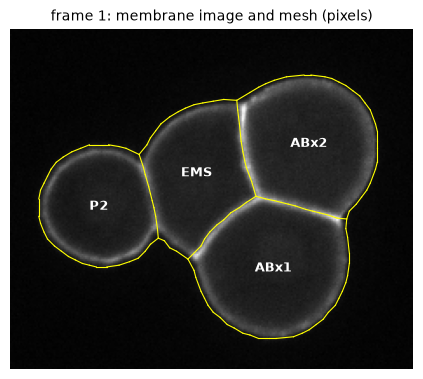

In [3]:
frame = 1  # normalised time closest to 0.5
mask, image = masks[frame], images[frame]
mesh = foambryo.dcel_mesh_from_segmentation_mask(mask, spacing=(um_per_pixel, um_per_pixel))
print(type(mesh).__name__, "dimension", foambryo.dimension_of(mesh))
print(len(mesh.points), "points,", len(mesh.segments), "segments, image shape", mesh.image_shape)

fig, ax = plt.subplots(figsize=(5.2, 4.5))
show_mask(ax, image, foambryo.dcel_mesh_from_segmentation_mask(mask), names, "frame 1: membrane image and mesh (pixels)")
plt.show()

## Tensions: the arc reading

Young's law at each junction where three interfaces meet, $\sum_k \gamma_k \mathbf{t}_k = 0$, with $\mathbf{t}_k$ the unit tangent of interface $k$ leaving the junction, is solved by least squares for the tensions $\gamma$, gauged to a mean of 1: the tensions are relative. The default reading in 2D, `angle_reading="arc"`, fits the geometric least-squares circle through each interface's mesh vertices and takes the tangent at the circle's point nearest the junction; an interface with fewer than 4 vertices is read by its chord. It assumes that each interface is a circular arc, which holds for a tissue near mechanical equilibrium whose cells are deformed by nothing but their own tensions and pressures.

In [4]:
tensions_arc = foambryo.infer_tensions(mesh)  # angle_reading=None is "arc" in 2D
for pair, tension in sorted(tensions_arc.items()):
    print(f"{name_of(pair, names):12s} {tension:6.3f}")

medium|EMS    0.642
medium|ABx1   1.124
medium|ABx2   1.029
medium|P2     0.773
EMS|ABx1      1.032
EMS|ABx2      0.941
EMS|P2        1.097
ABx1|ABx2     1.363


## Pressures: Laplace's law on the fitted circles

Each interface read by a circle of signed curvature $\kappa$ gives one row of Laplace's law, $\gamma\,\kappa = p_\text{left} - p_\text{right}$, with the medium held at `base_pressure` (0). In foambryo's convention for an interface $(a, b)$, $a < b$, this is $p_a - p_b = -\gamma_{ab}\,\kappa_{ab}$ with $\kappa_{ab}$ positive when the centre of curvature lies on $b$'s side, as $p_a - p_b = -2 H_{ab} \gamma_{ab}$ in 3D. The pressures are in units of the relative tension per micrometre, since the mesh is in micrometres. They are measurements only because this tissue is free: see the eggshell example for a tissue where they are not.

In [5]:
pressures_arc = foambryo.infer_pressures(mesh, tensions_arc)  # mode=None is Laplace in 2D
for cell, pressure in sorted(pressures_arc.items()):
    print(f"{names[cell]:7s} {pressure:7.4f} per um")

medium   0.0000 per um
EMS      0.0578 per um
ABx1     0.1002 per um
ABx2     0.0943 per um
P2       0.0880 per um


## Tensions, pressures and stresses in the viewer

`plot_force_inference` draws a 2D mesh in Polyscope's 2D window: the interfaces coloured by tension, the junctions, and each cell's mean stress tensor $\sigma = -p\,I + \frac{1}{A}\sum_m \gamma_m \sum_e l_e\, \mathbf{t}_e \mathbf{t}_e^\top$ (its principal axes scaled by their values; compression red, tension teal), with the image under it. `save_figure=..., show=False` writes the first view without opening the window. `foambryo view MESH --image IMAGE` opens the same window from the command line.

[polyscope] Backend: openGL3_glfw -- Loaded openGL version: 4.1 Metal - 91.7


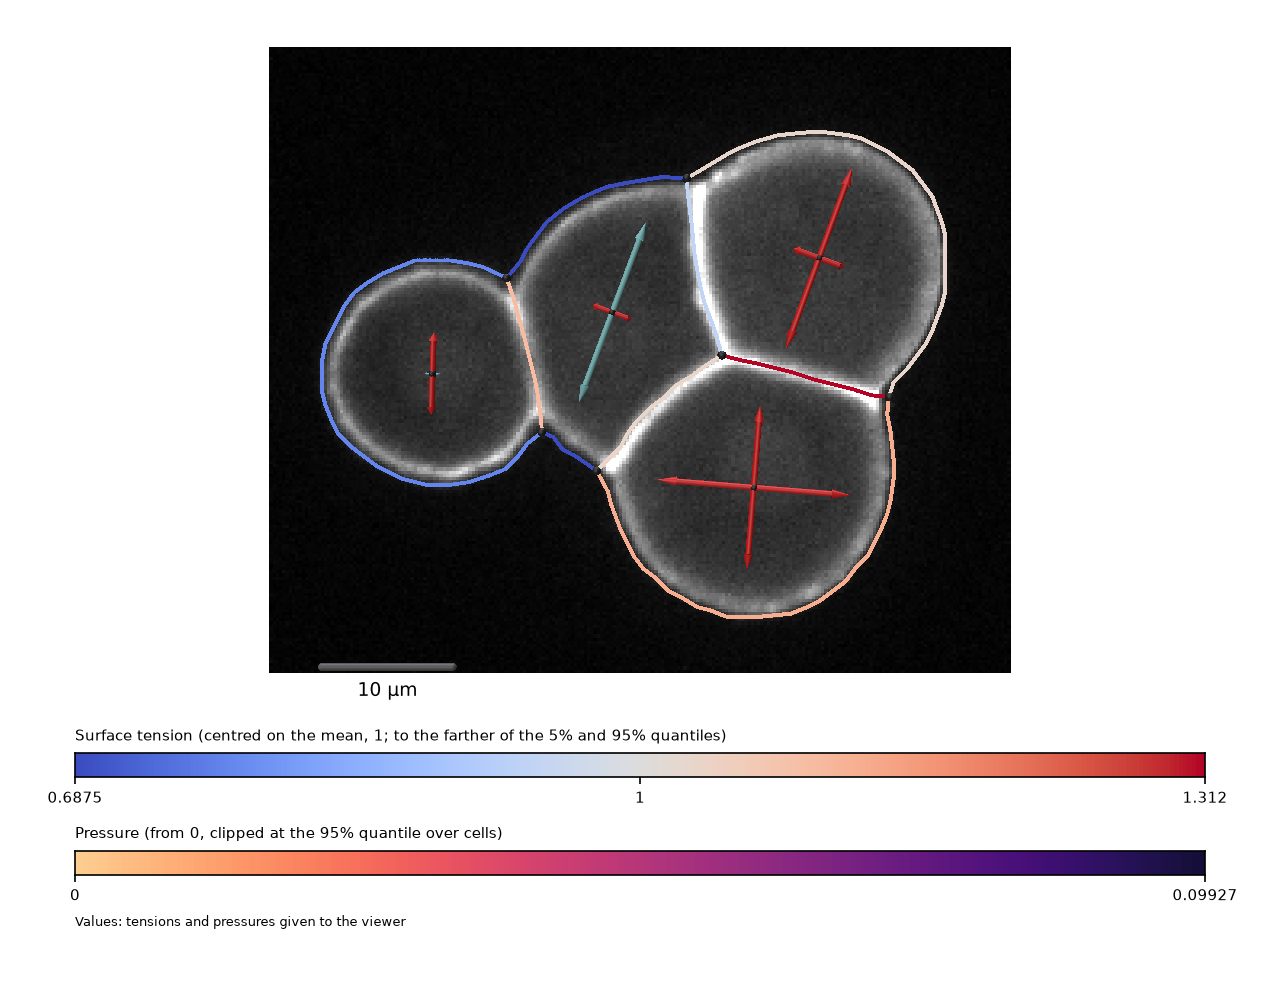

In [6]:
figure = FIGURES / "free_embryo_tensions_and_stresses.png"
plot_force_inference(mesh, tensions_arc, pressures_arc, image=image, length_unit="um", save_figure=figure, show=False)
display(Image(filename=figure, width=700))

## The opt-in global fit

`infer_forces_by_equilibrium_tiling(mesh, mask)` fits one equilibrium tiling of circular arcs to the mask's crack points (the middles of the sides shared by two pixels of different labels): every interface a circle, Young's and Laplace's laws exact at once (Noll, Streichan and Shraiman, *Phys. Rev. X* 10, 011072, 2020). It starts from the arc reading of the mesh. It is provisional and opt-in: on synthetic foams its tensions are more accurate than the arc reading's in almost every tier (see BENCHMARKS.md), but it refuses some images whole, which the arc reading does not. It needs the label image as well as the mesh, and like the arc reading it assumes circular interfaces, so it is not for confined tissues. It returns a `ComponentTensionSolution` (the tensions in `dict_tensions`), the pressures relative to the medium, and with `diagnostics=True` a report of what it refused and why.

In [7]:
tiling, pressures_tiling, report = foambryo.infer_forces_by_equilibrium_tiling(mesh, mask, diagnostics=True)
tensions_tiling = tiling.dict_tensions
print("valid tiling:", report.valid, "| converged:", report.converged, "| refused:", report.refused or "nothing")
print(f"{'interface':12s} {'arc':>6s} {'global fit':>11s}")
for pair in sorted(tensions_arc):
    print(f"{name_of(pair, names):12s} {tensions_arc[pair]:6.3f} {tensions_tiling[pair]:11.3f}")
print()
print(f"{'cell':7s} {'arc':>8s} {'global fit':>11s}  (per um)")
for cell in sorted(pressures_arc):
    print(f"{names[cell]:7s} {pressures_arc[cell]:8.4f} {pressures_tiling[cell]:11.4f}")

valid tiling: True | converged: True | refused: nothing
interface       arc  global fit
medium|EMS    0.642       0.536
medium|ABx1   1.124       1.111
medium|ABx2   1.029       1.128
medium|P2     0.773       0.556
EMS|ABx1      1.032       1.077
EMS|ABx2      0.941       1.064
EMS|P2        1.097       0.904
ABx1|ABx2     1.363       1.623

cell         arc  global fit  (per um)
medium    0.0000      0.0000
EMS       0.0578      0.0472
ABx1      0.1002      0.0998
ABx2      0.0943      0.1040
P2        0.0880      0.0633


## Three frames

The same two readings on the three frames of the file (normalised time 0.25, 0.49 and 0.75). Filled markers: the arc reading; open markers: the global fit.

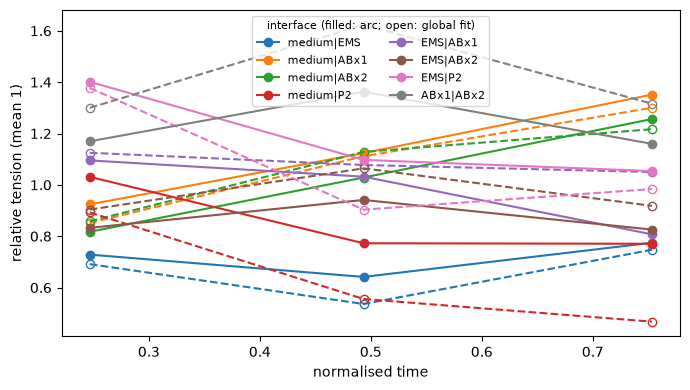

In [8]:
times = data["normalised_times"]
series = {"arc": {}, "global fit": {}}
for k in range(len(masks)):
    mesh_k = foambryo.dcel_mesh_from_segmentation_mask(masks[k], spacing=(um_per_pixel, um_per_pixel))
    arc_k = foambryo.infer_tensions(mesh_k)
    fit_k, _ = foambryo.infer_forces_by_equilibrium_tiling(mesh_k, masks[k])
    for pair in arc_k:
        series["arc"].setdefault(pair, []).append(arc_k[pair])
        series["global fit"].setdefault(pair, []).append(fit_k.dict_tensions.get(pair, np.nan))

fig, ax = plt.subplots(figsize=(7, 4))
colours = plt.cm.tab10(np.arange(10))
for i, pair in enumerate(sorted(series["arc"])):
    ax.plot(times, series["arc"][pair], "o-", color=colours[i], label=name_of(pair, names))
    ax.plot(times, series["global fit"][pair], "o--", mfc="none", color=colours[i])
ax.set_xlabel("normalised time")
ax.set_ylabel("relative tension (mean 1)")
ax.legend(fontsize=8, ncol=2, title="interface (filled: arc; open: global fit)", title_fontsize=8)
plt.tight_layout()
plt.show()

## Another reading of the same mesh

The chord reading of earlier versions, `angle_reading="chord"`, takes each tangent along the interface's first edge at the junction. On synthetic foams it is less accurate than the arc reading (BENCHMARKS.md); on this real mask it gives different numbers:

In [9]:
tensions_chord = foambryo.infer_tensions(mesh, angle_reading="chord")
print(f"{'interface':12s} {'arc':>6s} {'chord':>6s} {'global fit':>11s}")
for pair in sorted(tensions_arc):
    print(f"{name_of(pair, names):12s} {tensions_arc[pair]:6.3f} {tensions_chord[pair]:6.3f} {tensions_tiling[pair]:11.3f}")

interface       arc  chord  global fit
medium|EMS    0.642  1.181       0.536
medium|ABx1   1.124  1.215       1.111
medium|ABx2   1.029  1.273       1.128
medium|P2     0.773  1.293       0.556
EMS|ABx1      1.032  0.529       1.077
EMS|ABx2      0.941  0.576       1.064
EMS|P2        1.097  1.406       0.904
ABx1|ABx2     1.363  0.528       1.623


## What this shows, and what it does not

* The arc reading and the global fit both assume circular interfaces and a tissue deformed by its own forces only, which is why they are offered for a free embryo like this one. Both give tensions relative to their mean and pressures relative to the medium; neither gives absolute values (the paper calibrates them with myosin and atomic force microscopy).
* **An open question.** No real image has known tensions; the accuracy numbers of the readings (BENCHMARKS.md) were measured on synthetic foams. On this real mask (one embryo, one frame) the chord reading, printed above, gives three of the four cell–cell interfaces 0.39 to 0.61 times the tension the arc reading gives them: the chord reads only each interface's first edge at the junction, the arc reading a circle through the whole interface. Which of the two is closer to the truth on real free tissues is not known.
* The mask's cell–medium boundaries lie about 1 to 2 px outside the membrane (see the data's README), which moves the junction angles at the cell–medium interfaces.
* The pressures and the full stress are measurements only for a tissue deformed by nothing but its own tensions and pressures. In an embryo inside its eggshell the cells are compressed against the shell: see `choosing_an_angle_reading_inside_an_eggshell.ipynb`, which reads the tensions with the chord and computes no pressures.